# Customer Retention & Revenue Analysis Using Python

## 1. Project Overview

### Business Problem

Understanding customer purchasing behavior is essential for identifying revenue opportunities and improving customer retention.

This project analyzes historical retail transaction data to investigate sales performance, repeat purchasing behavior, and customer retention patterns.

### Project Objectives

- Assess and clean transaction data to support reliable analysis.
- Evaluate sales performance and revenue trends.
- Identify repeat customers and measure customer retention.
- Explore purchasing patterns and customer spending behavior.
- Develop actionable business recommendations based on the findings.

### Dataset

**Source:** UCI Machine Learning Repository — Online Retail Dataset

**Period:** December 2010 – December 2011

**Original dataset:** 541,909 transaction line items across 8 columns.

The dataset contains invoice numbers, product information, quantities, transaction dates, unit prices, customer identifiers, and countries.

### Tools

- Python
- pandas
- Jupyter Notebook
- Matplotlib / Seaborn (for visualizations)

### Analytical Approach

The analysis begins with data exploration and quality assessment, followed by data cleaning, revenue analysis, customer retention analysis, and business recommendations.

The original dataset will be preserved, with separate analytical datasets created where different business questions require different cleaning decisions.

## Executive Summary

This project analyzes transaction data from the UCI Online Retail dataset to evaluate revenue performance, customer purchasing behavior, and retention patterns from December 2010 through December 2011.

Using Python, pandas, and Matplotlib, the analysis identifies opportunities to strengthen repeat purchasing and better understand the customers contributing most to sales.

### Key Findings

**1. Revenue performance**

- The retailer generated approximately **£10.67 million in gross positive sales revenue** during the observed period.
- **November 2011** recorded the highest monthly sales at approximately **£1.51 million**.
- Revenue increased substantially during September–November 2011, highlighting the importance of understanding late-year demand.

**2. Repeat customers drive most identifiable-customer revenue**

- **65.58%** of identifiable customers made purchases on at least two distinct invoices.
- Repeat customers contributed **93.08%** of revenue attributable to identifiable customers.
- Repeat customers had a higher average order value (**£486.83**) than one-time customers (**£412.80**).

**3. Revenue is concentrated among high-value customers**

- The top **10% of identifiable customers** generated approximately **61.38%** of identifiable-customer revenue.
- This concentration suggests that understanding and supporting high-value customer relationships may be particularly important.

**4. Retention varies across months and customer cohorts**

- Consecutive-month customer retention ranged from **31.21% to 45.60%** across the complete-month comparisons analyzed.
- First-month cohort retention also varied considerably, ranging from **15.04% to 36.61%**.
- Customers sometimes returned after skipping a month, reinforcing the value of analyzing retention over multiple periods.

### Business Recommendations

1. **Strengthen early repeat purchasing:** Test targeted follow-up communications and relevant product recommendations.
2. **Understand high-value customers:** Investigate the purchasing characteristics of customers contributing disproportionately to revenue.
3. **Plan for seasonal demand:** Examine the factors associated with stronger sales during September–November.
4. **Monitor retention over time:** Track cohort-based retention metrics to evaluate changes in purchasing behavior.

### Important Limitations

Revenue represents positive-value sales before accounting for refunds, cancellations, costs, or profit.

Customer-level findings exclude transactions without identifiable customer IDs. The dataset also begins in December 2010 and ends on December 9, 2011, limiting conclusions about customers' earlier purchasing history and December 2011 performance.

These findings are observational and do not establish causation.

## 2. Data Exploration

### 2.1 Loading and Inspecting the Dataset

The analysis begins by loading the original retail transaction dataset into pandas and examining its structure.

The dataset contains **541,909 transaction line items and 8 columns**.

Each row represents a product line within an invoice rather than a unique customer order. Multiple rows may therefore share the same invoice number.

The initial exploration examines:

- The dataset's dimensions and available variables.
- The structure of transaction records.
- Missing values and potential data-quality issues.

Understanding the dataset's structure is necessary before calculating business metrics, particularly because counting transaction line items is different from counting unique orders or customers.

In [19]:
# Import pandas for data cleaning and analysis
import pandas as pd

# Load the original retail transaction dataset
df = pd.read_excel("Online Retail.xlsx")

# Preview the first five rows to understand the dataset structure
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [20]:
# Check the number of rows and columns in the dataset
df.shape

(541909, 8)

## 3. Data Quality Assessment

Before calculating revenue and customer retention metrics, the dataset was examined for missing values, cancelled transactions, and unusual quantities.

### 3.1 Missing Values

The initial assessment identified:

| Column | Missing Values |
|---|---:|
| CustomerID | 135,080 |
| Description | 1,454 |
| All other columns | 0 |

Approximately **24.9% of transaction line items** have missing customer identifiers.

**Business implications:**

Missing customer IDs prevent reliable identification of repeat customers and could affect retention calculations. However, these transactions may still contain useful sales information.

Therefore, the original records will be preserved, and customer-level analyses will use a separate dataset containing identifiable customers.

### 3.2 Cancelled Transactions and Negative Quantities

Further investigation identified:

| Data Quality Issue | Line Items |
|---|---:|
| Cancelled invoices (beginning with C) | 9,288 |
| Negative quantities | 10,624 |
| Negative quantities without cancellation markers | 1,336 |

All 1,336 negative-quantity records without cancellation markers have zero unit prices and missing customer IDs. Of these, 862 also have missing product descriptions.

These records may represent inventory adjustments or other non-sales activity, although their exact purpose cannot be confirmed from the available data.

**Analytical implication:** These records should not be treated as completed, positive-value customer purchases.

The analysis will distinguish valid sales transactions from cancellations and other non-sales records to avoid misleading revenue and retention metrics.

In [21]:
# Count missing values in each column
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [22]:
# Count records with missing customer IDs
df["CustomerID"].isna().sum()

np.int64(135080)

In [23]:
# Count transaction line items belonging to cancelled invoices
cancelled_count = df["InvoiceNo"].astype(str).str.startswith("C").sum()
print("Cancelled transaction line items:", cancelled_count)

Cancelled transaction line items: 9288


In [24]:
# Count transaction line items with negative quantities
negative_quantity_count = (df["Quantity"] < 0).sum()
print("Negative quantity records:", negative_quantity_count)

Negative quantity records: 10624


In [25]:
# Identify negative-quantity records not marked as cancellations
negative_non_cancelled = df[(df["Quantity"] < 0) &(~df["InvoiceNo"].astype(str).str.startswith("C"))]

# Preview these unusual transactions
negative_non_cancelled.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom


In [26]:
# Count negative-quantity records not marked as cancellations
print("Total unusual records:", len(negative_non_cancelled))

# Check how many have a zero unit price
print("Zero unit prices:", (negative_non_cancelled["UnitPrice"] == 0).sum())

# Check how many have missing customer IDs
print("Missing customer IDs:", negative_non_cancelled["CustomerID"].isna().sum())

# Check how many have missing descriptions
print("Missing descriptions:", negative_non_cancelled["Description"].isna().sum())

Total unusual records: 1336
Zero unit prices: 1336
Missing customer IDs: 1336
Missing descriptions: 862


## 4. Data Cleaning

### 4.1 Preparing the Sales Dataset

To calculate revenue from completed, positive-value sales, a separate DataFrame named `sales_df` was created.

The following criteria were applied:

- **Positive quantities:** Retain transaction line items with `Quantity > 0`.
- **Positive unit prices:** Retain records with `UnitPrice > 0`.
- **Exclude cancellations:** Remove invoice line items where `InvoiceNo` begins with `C`.

The original DataFrame (`df`) was preserved to support further investigation and alternative analyses.

### Cleaning Results

| Metric | Transaction Line Items |
|---|---:|
| Original dataset | 541,909 |
| Cleaned sales dataset | 530,104 |
| Excluded records | 11,805 |

Approximately **2.18% of transaction line items** were excluded.

### Business Rationale

The cleaned dataset provides a consistent basis for analyzing positive-value sales activity without mixing in cancelled transactions, negative quantities, or zero-priced records.

Transactions with missing customer IDs were not automatically excluded because they may still contribute to revenue analysis.

A separate customer-level dataset will be prepared later for retention analysis.

**Limitation:** The resulting revenue figures will represent positive-value sales before separately accounting for the financial impact of cancellations and returns. They should not automatically be interpreted as net revenue.

In [27]:
# Create a separate dataset containing positive-quantity,
# positive-price transactions that are not marked as cancellations
sales_df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0) & (~df["InvoiceNo"].astype(str).str.startswith("C"))].copy()

# Check how many transaction line items remain
sales_df.shape

(530104, 8)

## 5. Revenue Analysis

### 5.1 Calculating Sales Revenue

**Business Question:** How much positive-value sales revenue did the retailer generate during the dataset period?

Revenue is calculated for each transaction line item using:

**Revenue = Quantity × UnitPrice**

This metric provides the foundation for evaluating overall sales performance, monthly revenue trends, and customer purchasing behavior.

**Methodology:** Revenue calculations use the cleaned `sales_df` dataset, which excludes cancelled invoices, negative quantities, and zero-priced transactions.

The results represent positive-value sales rather than net revenue after returns and cancellations.

In [28]:
# Calculate revenue for each transaction line item
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Preview the calculation to verify the results
sales_df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [29]:
# Calculate total positive-value sales revenue
total_revenue = sales_df["Revenue"].sum()

# Display the result in British pounds
print(f"Total Sales Revenue: £{total_revenue:,.2f}")

Total Sales Revenue: £10,666,684.54


### 5.2 Total Sales Revenue — Key Finding

**Result:** The retailer recorded approximately **£10.67 million in positive-value sales revenue** during the dataset period.

This figure was calculated by multiplying quantity by unit price for each qualifying transaction line item and summing the results.

**Business interpretation:**

The result establishes a baseline for evaluating sales performance. However, total revenue alone does not explain whether sales were growing, declining, or concentrated among particular customers.

Further analysis will investigate monthly revenue trends and customer purchasing behavior to identify potential business opportunities.

**Limitation:** This figure excludes cancelled transactions, returns, and zero-priced records. It represents positive-value sales rather than net revenue or profit.

### 5.3 Monthly Revenue Trends

**Business Question:** How did positive-value sales revenue change over time?

Analyzing monthly revenue can help identify periods of growth, decline, and potential seasonality.

**Methodology:** Transaction dates will be grouped by calendar month, and revenue will be summed for each period.

Because the dataset covers December 2010 through December 2011, the first and last months may not represent complete calendar months. This limitation will be considered when interpreting trends.

In [30]:
# Convert invoice dates to monthly periods
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Preview the new column
sales_df[["InvoiceDate", "YearMonth"]].head()

,InvoiceDate,YearMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [31]:
# Group sales by month and calculate total revenue
monthly_revenue = (sales_df.groupby("YearMonth")["Revenue"].sum().reset_index())

# Display monthly revenue with two decimal places
monthly_revenue["Revenue"] = monthly_revenue["Revenue"].round(2)
monthly_revenue

,YearMonth,Revenue
0,2010-12,823746.14
1,2011-01,691364.56
2,2011-02,523631.89
3,2011-03,717639.36
4,2011-04,537808.62
5,2011-05,770536.02
6,2011-06,761739.90
7,2011-07,719221.19
8,2011-08,759138.38
9,2011-09,1058590.17


Matplotlib is building the font cache; this may take a moment.


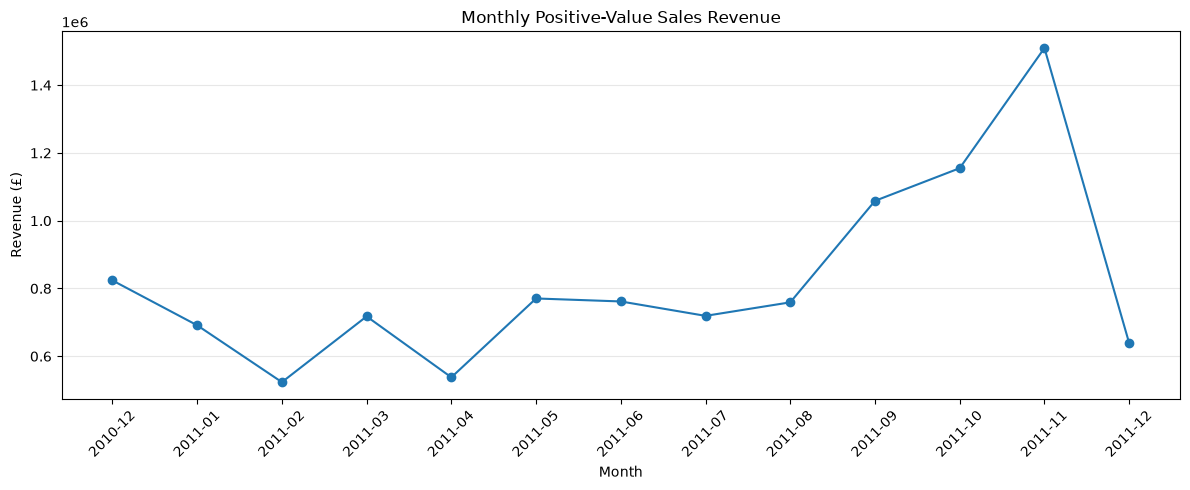

In [34]:
# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Create a line chart of monthly revenue
plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue["YearMonth"].astype(str),monthly_revenue["Revenue"],marker="o")

# Add descriptive labels
plt.title("Monthly Positive-Value Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

# Make the month labels easier to read
plt.xticks(rotation=45)

# Improve spacing and readability
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### 5.4 Monthly Revenue — Key Findings

**Key Findings**

- **Peak sales month:** November 2011 generated approximately **£1.51 million**, the highest monthly positive-value sales revenue in the dataset.
- **Lowest complete month:** February 2011 generated approximately **£523,632**.
- **Late-year growth:** Revenue increased substantially from September through November 2011, indicating a potential seasonal sales pattern.

**Business Interpretation**

The late-year increase suggests that demand may be stronger during the months leading up to the holiday season. This pattern could inform inventory planning, staffing, and marketing decisions.

However, additional years of data would be needed to confirm whether this is a recurring seasonal trend.

**Data Limitation**

December 2011 contains only a partial month of transactions. Its apparent revenue decline should not be interpreted as evidence of deteriorating business performance.

**Business Recommendation**

Investigate which products and customer segments contributed most to the September–November revenue increase. This could help the retailer identify opportunities to prepare for future periods of high demand.

## 6. Customer Retention Analysis

### 6.1 Preparing Customer-Level Data

**Business Question:** How many identifiable customers made repeat purchases, and what percentage of customers returned?

Customer retention is important because repeat purchasing can indicate ongoing customer engagement and opportunities for long-term revenue.

**Methodology:**

- Use the cleaned positive-value sales dataset.
- Exclude records with missing `CustomerID` from customer-level analysis.
- Identify unique customers using `CustomerID`.
- Identify distinct purchases using `InvoiceNo`, rather than counting individual product line items as separate orders.
- Classify customers with two or more distinct purchases as repeat purchasers.

**Limitation:** Customers without an identifiable `CustomerID` cannot be included in repeat-purchase calculations. Additionally, the dataset covers a limited observation period, so customers may have purchased before or after the available dates.

The repeat-purchase rate will describe observed purchasing behavior within the dataset, rather than a formal cohort retention rate.

In [35]:
# Keep only sales transactions with an identifiable customer
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

# Compare the number of transaction line items
print(f"All sales line items: {len(sales_df):,}")
print(f"Identifiable customer line items: {len(customer_df):,}")

# Count the unique customers we can analyze
print(f"Unique customers: {customer_df['CustomerID'].nunique():,}")

All sales line items: 530,104
Identifiable customer line items: 397,884
Unique customers: 4,338


In [36]:
# Count distinct invoices for each identifiable customer
customer_orders = (customer_df.groupby("CustomerID")["InvoiceNo"].nunique().reset_index(name="OrderCount"))

# Preview the number of purchases per customer
customer_orders.head(10)

,CustomerID,OrderCount
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
5,12352.0,8
6,12353.0,1
7,12354.0,1
8,12355.0,1
9,12356.0,3


In [37]:
# Count customers with at least two distinct purchases
repeat_customers = (customer_orders["OrderCount"] >= 2).sum()

# Count all identifiable customers
total_customers = len(customer_orders)

# Calculate the repeat-purchase rate
repeat_purchase_rate = (repeat_customers / total_customers) * 100

# Display the results
print(f"Total Customers: {total_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%")

Total Customers: 4,338
Repeat Customers: 2,845
Repeat Purchase Rate: 65.58%


### 6.2 Repeat-Purchase Rate — Key Finding

**Business Question:** What percentage of identifiable customers made more than one purchase?

**Results:**

- Total identifiable customers: **4,338**
- Customers with two or more distinct purchases: **2,845**
- Customers with only one purchase: **1,493**
- Repeat-purchase rate: **65.58%**

**Business Interpretation**

Approximately two-thirds of identifiable customers made multiple purchases during the observed period, indicating that repeat purchasing was common among the retailer's known customers.

However, approximately **34.42%** made only one observed purchase. This group may represent an opportunity for targeted follow-up marketing and customer re-engagement.

**Business Recommendation**

Investigate the purchasing patterns of one-time customers and compare them with repeat purchasers. Understanding differences in order frequency, spending, and purchase timing could help identify opportunities to encourage additional purchases.

**Limitations**

This metric excludes transactions without customer IDs and measures repeat purchasing within the available dataset only.

It is not a formal cohort retention rate and does not establish whether customers returned within a specific time frame. Customers observed making one purchase may have purchased outside the dataset's observation period.

In [38]:
# Classify customers based on their number of purchases
customer_orders["CustomerType"] = customer_orders["OrderCount"].apply(lambda count: "Repeat Customer" if count >= 2 else "One-Time Customer")

# Check the number of customers in each group
customer_orders["CustomerType"].value_counts()

CustomerType
Repeat Customer      2845
One-Time Customer    1493
Name: count, dtype: int64

In [39]:
# Add customer type to each transaction line item
customer_revenue_df = customer_df.merge(customer_orders[["CustomerID", "CustomerType"]],on="CustomerID",how="left",validate="many_to_one")

# Calculate total revenue for each customer type
revenue_by_type = (customer_revenue_df.groupby("CustomerType")["Revenue"].sum().reset_index())

# Calculate each group's share of identifiable-customer revenue
revenue_by_type["RevenueShare"] = (revenue_by_type["Revenue"] / revenue_by_type["Revenue"].sum() * 100)

# Display the results
revenue_by_type.round(2)

,CustomerType,Revenue,RevenueShare
0,One-Time Customer,616311.73,6.92
1,Repeat Customer,8295096.17,93.08


### 6.3 Revenue Contribution by Customer Type

**Business Question:** How much revenue is generated by repeat customers compared with one-time customers?

**Key Findings**

| Metric | Repeat Customers | One-Time Customers |
|---|---:|---:|
| Number of customers | 2,845 | 1,493 |
| Share of customers | 65.58% | 34.42% |
| Positive-value sales revenue | £8,295,096.17 | £616,311.73 |
| Share of identifiable-customer revenue | 93.08% | 6.92% |

**Business Interpretation**

Repeat customers generated approximately **£8.30 million**, accounting for **93.08% of revenue linked to identifiable customers**.

Although repeat customers represented approximately two-thirds of identifiable customers, they contributed more than nine-tenths of the group's revenue.

This demonstrates that customers who purchased multiple times were particularly important to the retailer's observed sales performance.

**Business Recommendation**

Prioritize understanding and supporting repeat purchasing through initiatives such as personalized follow-up communications, relevant product recommendations, and targeted re-engagement campaigns.

Investigate whether one-time customers can be encouraged to make additional purchases, while also identifying which existing repeat customers contribute the most revenue.

**Limitations**

- Revenue from transactions without customer IDs is excluded from this comparison.
- The figures represent positive-value sales, not net revenue or profit.
- Repeat customers have more orders by definition. Their larger revenue contribution does not establish that they spend more per order.
- This observational analysis does not demonstrate that a retention campaign would cause additional purchases.

In [40]:
# Calculate revenue for each distinct customer invoice
order_revenue = (customer_revenue_df.groupby(["CustomerID", "InvoiceNo", "CustomerType"])["Revenue"].sum().reset_index())

# Calculate average order value for each customer type
average_order_value = (order_revenue.groupby("CustomerType")["Revenue"].agg(TotalRevenue="sum",TotalOrders="count",AverageOrderValue="mean").reset_index())

# Display results rounded to two decimal places
average_order_value.round(2)

,CustomerType,TotalRevenue,TotalOrders,AverageOrderValue
0,One-Time Customer,616311.73,1493,412.80
1,Repeat Customer,8295096.17,17039,486.83


### 6.4 Average Order Value by Customer Type

**Business Question:** Do repeat customers spend more per order than one-time customers?

**Key Findings**

| Metric | Repeat Customers | One-Time Customers |
|---|---:|---:|
| Total orders | 17,039 | 1,493 |
| Average order value | £486.83 | £412.80 |

Repeat customers had an average order value approximately **£74.03 (17.93%) higher** than one-time customers.

**Business Interpretation**

Repeat customers generated more revenue through both higher purchase frequency and larger average order values.

This suggests that repeat purchasers are an important customer segment for the retailer's revenue performance.

However, the analysis shows an association rather than a causal relationship. Customers may differ in purchasing needs, business size, or other characteristics that influence order value.

**Business Recommendation**

Explore opportunities to encourage second purchases among one-time customers while maintaining relationships with existing repeat customers.

Further analysis should examine customer spending patterns and identify whether a small group of high-value customers accounts for a disproportionate share of revenue.

**Limitations**

- Only transactions linked to identifiable customers are included.
- Average order value is based on positive-value sales, excluding returns and cancellations.
- Large orders may influence the average. Median order value could provide additional context.
- Higher spending among repeat customers does not prove that repeat purchasing causes larger orders.

In [41]:
# Calculate total positive-value sales revenue per customer
customer_spending = (customer_df.groupby("CustomerID")["Revenue"].sum().reset_index(name="TotalRevenue"))

# Sort customers from highest to lowest revenue
customer_spending = customer_spending.sort_values(by="TotalRevenue",ascending=False).reset_index(drop=True)

# Preview the 10 highest-spending customers
customer_spending.head(10).round(2)

,CustomerID,TotalRevenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194550.79
3,16446.0,168472.50
4,14911.0,143825.06
5,12415.0,124914.53
6,14156.0,117379.63
7,17511.0,91062.38
8,16029.0,81024.84
9,12346.0,77183.60


In [42]:
# Import math to round up the number of customers
import math

# Calculate how many customers represent the top 10%
top_10_count = math.ceil(len(customer_spending) * 0.10)

# Calculate revenue generated by the top 10% of customers
top_10_revenue = customer_spending.head(top_10_count)["TotalRevenue"].sum()

# Calculate total revenue from identifiable customers
total_customer_revenue = customer_spending["TotalRevenue"].sum()

# Calculate the top 10% revenue share
top_10_revenue_share = (top_10_revenue / total_customer_revenue) * 100

# Display results
print(f"Total Identifiable Customers: {len(customer_spending):,}")
print(f"Customers in Top 10%: {top_10_count:,}")
print(f"Revenue from Top 10%: £{top_10_revenue:,.2f}")
print(f"Top 10% Revenue Share: {top_10_revenue_share:.2f}%")

Total Identifiable Customers: 4,338
Customers in Top 10%: 434
Revenue from Top 10%: £5,469,382.46
Top 10% Revenue Share: 61.38%


### 6.5 Customer Revenue Concentration

**Business Question:** How much revenue is generated by the highest-spending 10% of identifiable customers?

**Key Findings**

- Total identifiable customers: **4,338**
- Customers in the top 10%: **434**
- Revenue generated by the top 10%: **£5,469,382.46**
- Share of identifiable-customer revenue: **61.38%**

**Business Interpretation**

The highest-spending 10% of identifiable customers generated more than 60% of the group's positive-value sales revenue.

This indicates substantial customer revenue concentration, meaning the retailer's sales performance is disproportionately influenced by a relatively small customer segment.

**Business Recommendations**

- Develop strategies to maintain relationships with high-value customers, such as proactive customer support and relevant product recommendations.
- Investigate whether customers outside the top 10% have opportunities to increase their purchasing frequency.
- Monitor changes in revenue concentration over time to identify potential dependence on a small number of customers.

**Limitations**

- This analysis excludes transactions without identifiable customer IDs.
- Revenue represents positive-value sales, not net revenue or profit.
- High spending does not necessarily indicate high profitability.
- The analysis measures spending concentration during the observed period, not the likelihood of customer churn.

### 6.6 Month-to-Month Customer Retention

**Business Question:** What percentage of customers who purchased in a given month returned to make another purchase in the following calendar month?

**Methodology**

- Use positive-value sales transactions linked to identifiable customers.
- Count each customer only once per calendar month, regardless of how many orders they placed.
- Identify customers who made purchases in consecutive calendar months.
- Calculate the percentage of customers active in one month who also purchased in the next month.

**Retention Formula**

Month-to-Month Retention Rate = (Customers purchasing in both Month A and Month B ÷ Customers purchasing in Month A) × 100

**Business Value**

This metric helps evaluate how consistently customers return and whether repeat purchasing behavior changes over time.

**Limitations**

This is a consecutive-month retention measure, not cohort retention. Customers who return after skipping a month will not count as retained for that particular month-to-month comparison.

The final observed month cannot be evaluated for next-month retention because the dataset does not include the following month.

In [43]:
# Create a separate dataset for monthly customer activity
monthly_customers = customer_df.copy()

# Extract the calendar month from each transaction date
monthly_customers["YearMonth"] = (monthly_customers["InvoiceDate"].dt.to_period("M"))

# Keep one record per customer per month
monthly_customers = (monthly_customers[["CustomerID", "YearMonth"]].drop_duplicates().sort_values(["YearMonth", "CustomerID"]).reset_index(drop=True))

# Preview the results
monthly_customers.head(10)

,CustomerID,YearMonth
0,12347.0,2010-12
1,12348.0,2010-12
2,12370.0,2010-12
3,12377.0,2010-12
4,12383.0,2010-12
5,12386.0,2010-12
6,12395.0,2010-12
7,12417.0,2010-12
8,12423.0,2010-12
9,12427.0,2010-12


In [44]:
# Create a copy representing the following month's activity
next_month_customers = monthly_customers.copy()

# Shift each activity month backward by one month
next_month_customers["YearMonth"] = (next_month_customers["YearMonth"] - 1)

# Match customers active in a month with those active the next month
retained_customers = monthly_customers.merge(next_month_customers, on=["CustomerID", "YearMonth"],how="inner")

# Preview customers who returned in consecutive months
retained_customers.head(10)

,CustomerID,YearMonth
0,12347.0,2010-12
1,12348.0,2010-12
2,12377.0,2010-12
3,12383.0,2010-12
4,12386.0,2010-12
5,12417.0,2010-12
6,12431.0,2010-12
7,12471.0,2010-12
8,12472.0,2010-12
9,12476.0,2010-12


In [45]:
# Count unique active customers in each month
monthly_active = (monthly_customers.groupby("YearMonth")["CustomerID"].nunique().reset_index(name="ActiveCustomers"))

# Count customers who returned the following month
monthly_retained = (retained_customers.groupby("YearMonth")["CustomerID"].nunique().reset_index(name="RetainedCustomers"))

# Combine active and retained customer counts
monthly_retention = monthly_active.merge(monthly_retained,on="YearMonth",how="left")

# Exclude the final month because the following month is unavailable
monthly_retention = monthly_retention[monthly_retention["YearMonth"] < monthly_retention["YearMonth"].max()].copy()

# Replace missing retained counts with zero
monthly_retention["RetainedCustomers"] = (monthly_retention["RetainedCustomers"].fillna(0).astype(int))

# Calculate month-to-month retention percentage
monthly_retention["RetentionRate"] = (monthly_retention["RetainedCustomers"]/ monthly_retention["ActiveCustomers"] * 100).round(2)

# Display the results
monthly_retention

,YearMonth,ActiveCustomers,RetainedCustomers,RetentionRate
0,2010-12,885,324,36.61
1,2011-01,741,262,35.36
2,2011-02,758,290,38.26
3,2011-03,974,304,31.21
4,2011-04,856,368,42.99
5,2011-05,1056,410,38.83
6,2011-06,991,365,36.83
7,2011-07,949,388,40.89
8,2011-08,935,425,45.45
9,2011-09,1266,489,38.63


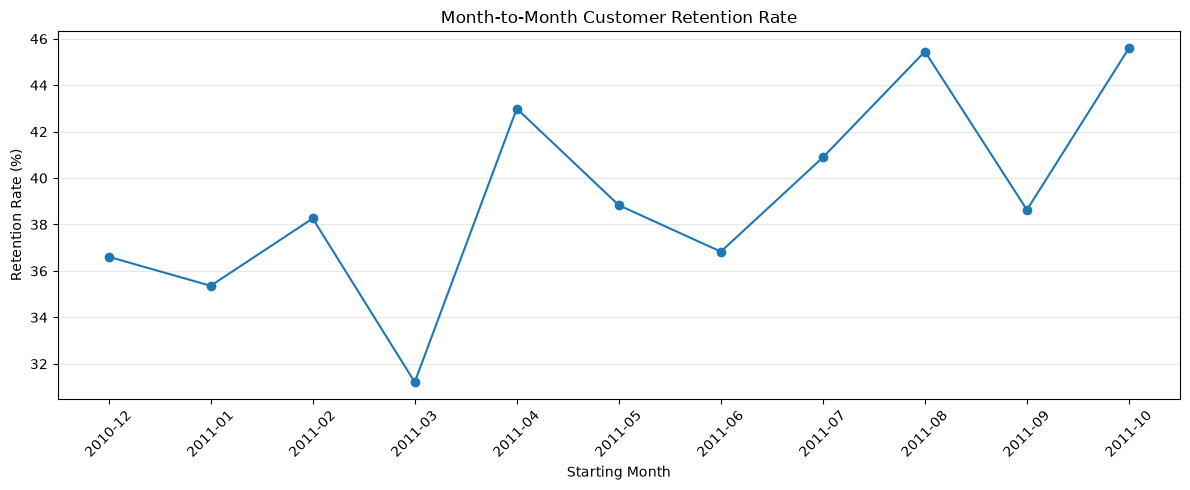

In [46]:
# Exclude November-to-December because December 2011 is incomplete
retention_chart_df = monthly_retention[monthly_retention["YearMonth"] < pd.Period("2011-11", freq="M")].copy()

# Create a line chart of month-to-month retention rates
plt.figure(figsize=(12, 5))

plt.plot(retention_chart_df["YearMonth"].astype(str),retention_chart_df["RetentionRate"],marker="o")

# Add descriptive labels
plt.title("Month-to-Month Customer Retention Rate")
plt.xlabel("Starting Month")
plt.ylabel("Retention Rate (%)")

# Improve readability
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### 6.7 Month-to-Month Retention — Key Findings

**Business Question:** How consistently did customers return to purchase in the following month?

**Key Findings**

- **Highest retention:** October to November 2011, at **45.60%** (622 of 1,364 customers).
- **Lowest retention:** March to April 2011, at **31.21%** (304 of 974 customers).
- **Overall pattern:** Month-to-month retention fluctuated throughout the observation period, rather than following a consistent upward or downward trend.

**Business Interpretation**

The retailer experienced considerable variation in the proportion of customers returning in consecutive months.

The October-to-November period showed the strongest observed retention among complete-month comparisons, coinciding with the retailer's high-revenue period.

However, the analysis does not establish whether seasonal demand, marketing activity, or other factors caused these differences.

**Business Recommendations**

- Investigate what distinguishes higher-retention months from lower-retention months.
- Examine whether customer segments differ in their likelihood of purchasing in consecutive months.
- Consider testing targeted follow-up communications to encourage customers to make another purchase.

**Limitations**

- Only identifiable customers with positive-value sales are included.
- Customers who skip a month and return later are not counted as retained in that particular comparison.
- The November-to-December 2011 comparison is excluded from the chart and performance conclusions because December 2011 is incomplete.
- These results describe observed purchasing behavior, not the causal impact of retention initiatives.

### 6.8 Customer Cohort Retention Analysis

**Business Question:** How does customer retention change over time for customers grouped by their first observed purchase month?

**Methodology**

- Assign each identifiable customer to a cohort based on their first observed purchase month.
- Track customer purchasing activity in subsequent calendar months.
- Calculate the percentage of each cohort that purchased again in each subsequent month.
- Visualize the results using a cohort retention heatmap.

**Retention Formula**

Cohort Retention Rate = (Customers from the original cohort active in a given month ÷ Total customers in that cohort) × 100

**Business Value**

Cohort analysis helps identify whether newer customer groups exhibit different repeat-purchasing patterns and how purchasing activity changes as time passes after their first observed transaction.

**Limitations**

- The dataset begins in December 2010, so a customer's first observed purchase may not be their actual first purchase.
- Later cohorts have fewer months of observable activity.
- The incomplete final month (December 2011) must be treated cautiously.
- Customers are considered active only in months when they make qualifying purchases; returning after a skipped month is allowed in this analysis.

In [47]:
# Find each customer's first observed purchase month
customer_cohorts = (monthly_customers.groupby("CustomerID")["YearMonth"].min().reset_index(name="CohortMonth"))

# Preview the customer cohort assignments
customer_cohorts.head(10)

,CustomerID,CohortMonth
0,12346.0,2011-01
1,12347.0,2010-12
2,12348.0,2010-12
3,12349.0,2011-11
4,12350.0,2011-02
5,12352.0,2011-02
6,12353.0,2011-05
7,12354.0,2011-04
8,12355.0,2011-05
9,12356.0,2011-01


In [48]:
# Add each customer's cohort month to their monthly activity
cohort_activity = monthly_customers.merge(customer_cohorts,on="CustomerID",how="left",validate="many_to_one")

# Preview the combined dataset
cohort_activity.head(10)

,CustomerID,YearMonth,CohortMonth
0,12347.0,2010-12,2010-12
1,12348.0,2010-12,2010-12
2,12370.0,2010-12,2010-12
3,12377.0,2010-12,2010-12
4,12383.0,2010-12,2010-12
5,12386.0,2010-12,2010-12
6,12395.0,2010-12,2010-12
7,12417.0,2010-12,2010-12
8,12423.0,2010-12,2010-12
9,12427.0,2010-12,2010-12


In [49]:
# Calculate the number of months since each customer's first observed purchase
cohort_activity["CohortIndex"] = ((cohort_activity["YearMonth"].dt.year -cohort_activity["CohortMonth"].dt.year) * 12 
                                  + (cohort_activity["YearMonth"].dt.month - cohort_activity["CohortMonth"].dt.month))

# Preview the results
cohort_activity.head(10)

,CustomerID,YearMonth,CohortMonth,CohortIndex
0,12347.0,2010-12,2010-12,0
1,12348.0,2010-12,2010-12,0
2,12370.0,2010-12,2010-12,0
3,12377.0,2010-12,2010-12,0
4,12383.0,2010-12,2010-12,0
5,12386.0,2010-12,2010-12,0
6,12395.0,2010-12,2010-12,0
7,12417.0,2010-12,2010-12,0
8,12423.0,2010-12,2010-12,0
9,12427.0,2010-12,2010-12,0


In [50]:
# Count active customers for each cohort and month since first purchase
cohort_counts = (cohort_activity.groupby(["CohortMonth", "CohortIndex"])["CustomerID"].nunique().reset_index(name="ActiveCustomers"))

# Arrange the results into a cohort table
cohort_table = cohort_counts.pivot(index="CohortMonth",columns="CohortIndex",values="ActiveCustomers")

# Display the cohort activity table
cohort_table

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [51]:
# Get the original number of customers in each cohort
cohort_sizes = cohort_table[0]

# Calculate retention percentages for each cohort
cohort_retention = (cohort_table.div(cohort_sizes, axis=0) * 100).round(2)

# Display the retention percentage table
cohort_retention

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
# Create a copy for the final cohort retention visualization
cohort_retention_chart = cohort_retention.copy()

# Identify the incomplete final calendar month
incomplete_month = pd.Period("2011-12", freq="M")

# Remove observations that fall in December 2011
for cohort_month in cohort_retention_chart.index:
    for cohort_index in cohort_retention_chart.columns:
        activity_month = cohort_month + cohort_index
        if activity_month >= incomplete_month:
            cohort_retention_chart.loc[
                cohort_month, cohort_index
            ] = float("nan")

# Remove the incomplete December 2011 cohort
cohort_retention_chart = cohort_retention_chart.loc[cohort_retention_chart.index < incomplete_month]

# Display the adjusted retention table
cohort_retention_chart

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,NaN
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,NaN,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,NaN,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,NaN,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,NaN,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,NaN,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


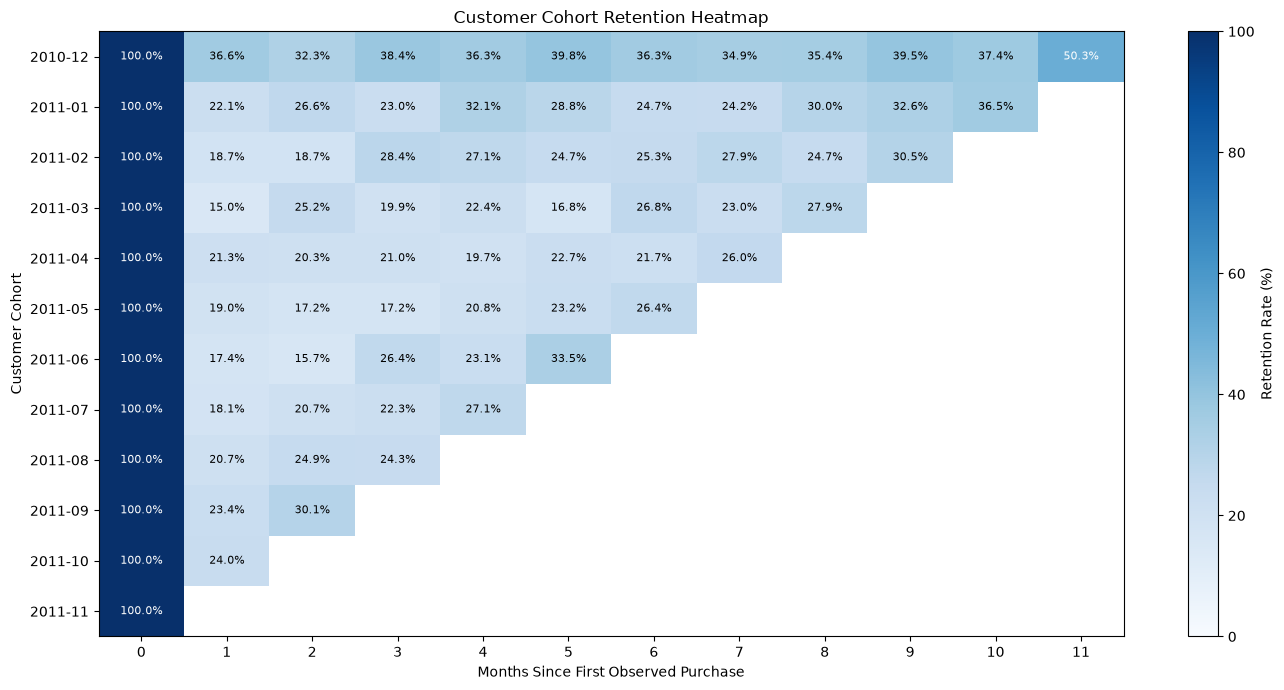

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# Remove the unused Month 12 column
heatmap_data = cohort_retention_chart.dropna(axis=1, how="all")

# Create the heatmap
fig, ax = plt.subplots(figsize=(14, 7))

heatmap = ax.imshow(np.ma.masked_invalid(heatmap_data.to_numpy()), cmap="Blues", aspect="auto", vmin=0, vmax=100)

# Label the axes
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index.astype(str))

ax.set_xlabel("Months Since First Observed Purchase")
ax.set_ylabel("Customer Cohort")
ax.set_title("Customer Cohort Retention Heatmap")

# Display retention percentages inside each available cell
for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[row, col]
        if not np.isnan(value):
            ax.text(col, row, f"{value:.1f}%", ha="center", va="center", fontsize=8, color="white" if value >= 50 else "black")

# Add a color legend
colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Retention Rate (%)")

plt.tight_layout()
plt.show()

### 6.9 Customer Cohort Retention — Key Findings

**Business Question:** How does purchasing activity change over time across customer cohorts?

**Key Findings**

- **First-month retention varied substantially:** Among cohorts with a complete following month, retention ranged from **15.04%** for March 2011 to **36.61%** for December 2010.
- **The December 2010 cohort showed relatively strong repeat purchasing:** More than 30% of its customers were active in every subsequent complete calendar month, reaching **50.28%** in Month 11.
- **Customers sometimes returned after inactive months:** Retention did not consistently decline as cohorts aged. For example, the January 2011 cohort had **22.06%** activity in Month 1 and **36.45%** in Month 10.
- **Cohort performance differed:** Customer groups exhibited different purchasing patterns, suggesting that retention should be evaluated by cohort rather than relying only on an overall repeat-purchase rate.

**Business Interpretation**

The analysis suggests opportunities to improve early repeat purchasing, particularly among cohorts with lower first-month retention.

However, differences between cohorts may reflect seasonality, customer composition, purchasing frequency, or other factors not measured in this analysis.

**Business Recommendations**

- **Improve early engagement:** Test follow-up communications or relevant product recommendations after customers' first observed purchases.
- **Investigate stronger cohorts:** Examine purchasing patterns and customer characteristics associated with higher retention.
- **Track retention by cohort:** Monitor Month 1, Month 2, and Month 3 retention to evaluate changes in customer purchasing behavior over time.

**Limitations**

- Cohorts are based on each customer's **first observed purchase**, not necessarily their first-ever purchase.
- The December 2010 cohort may contain established customers whose earlier transactions are unavailable.
- December 2011 observations are excluded because the dataset ends on December 9, 2011.
- Newer cohorts have shorter observation periods, so long-term retention cannot be compared across every cohort.
- These findings describe associations and do not establish the causes of retention differences.